# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
data = pandas.concat(
    [
        pandas.read_csv(
            'results/ModifyingOptions_5292.csv',
        ),
        pandas.read_csv(
            'results/ModifyingOptions_More_5292.csv',
        )
    ],
    ignore_index = True,
).drop_duplicates(['problem', 'strategy'], keep = 'last')

data = data[data.problem.isin(data[data.strategy == 'SATResetAtStaleBacktrack'].problem)]

In [5]:
problems = data.problem.str[:3].value_counts().sort_index()
pandas.concat(
    [
        problems[0::3].reset_index(),
        problems[1::3].reset_index(),
        problems[2::3].reset_index(),
    ],
    axis = 1,
).fillna('')

,problem,count,problem,count,problem,count
0,AGT,306,ALG,2465,ANA,493.0
1,BIO,17,BOO,901,CAT,748.0
2,COL,1530,COM,493,CSR,2788.0
3,FLD,1428,GEO,4318,GRA,204.0
4,GRP,5797,HAL,85,HEN,289.0
5,HWC,17,HWV,1649,KLE,1207.0
6,KRS,1666,LAT,3927,LCL,4692.0
7,LDA,221,MED,51,MGT,1088.0
8,MSC,136,NLP,2839,NUM,5457.0
9,NUN,17,PHI,68,PLA,357.0


# Analysing

In [6]:
control = ['FirstAction', 'LeanCopCut']

In [7]:
data.groupby('strategy').problem.count()

strategy
AdaptiveReset                   5013
EntropyCut                      5013
HeuristicSelection              5013
LeanCoP                         5013
PyCoP                           5013
SATCoP                          5013
SATCoP_0                        5013
SATResetAtStaleAction           5013
SATResetAtStaleBacktrack        5013
SATResetBandit                  5013
SATSolveGuided                  5013
SATSolveGuidedEVSIDS            5013
SATSolveGuidedFast              5013
SATSolveGuidedForcedTrue        5013
SATSolveGuidedProbeConflicts    5013
SATSolveGuidedShort             5013
SmartCut                        5013
Name: problem, dtype: int64

In [8]:
pandas.crosstab(
    data.strategy,
    data.result,
    margins = True,
).sort_values('All')

result,Non-Theorem: no positive start clauses,Theorem,Theorem (SAT),All
strategy,,,,
PyCoP,12,269,0,281
AdaptiveReset,1,487,0,488
SmartCut,1,489,0,490
HeuristicSelection,1,567,0,568
EntropyCut,1,607,0,608
SATSolveGuidedProbeConflicts,1,0,618,619
SATSolveGuided,1,0,628,629
SATSolveGuidedForcedTrue,1,0,635,636
SATSolveGuidedEVSIDS,1,0,645,646


In [9]:
data[data.problem == 'PUZ053-1.p']

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error


In [10]:
pandas.crosstab(
    data.result.fillna('?'),
    data.problem_declared_status,
)

problem_declared_status,ContradictoryAxioms,CounterSatisfiable,Open,Satisfiable,Theorem,Unknown,Unsatisfiable
result,,,,,,,
?,1469,3468,255,6382,29913,4454,27883
Non-Theorem: no positive start clauses,0,0,0,27,0,0,1
Theorem,27,0,0,0,1923,0,1126
Theorem (SAT),102,0,0,0,4748,0,3443


In [11]:
data[data.solved]

,problem,strategy,status,result,solved,steps,time_ms,problem_spc_tags,problem_typed,problem_declared_status,problem_declared_status_kind,info,error
1,AGT001+1.p,LeanCoP,solved,Theorem,True,3.0,2.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN
2,AGT001+1.p,SATCoP_0,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN
3,AGT001+1.p,SATCoP,solved,Theorem (SAT),True,0.0,0.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN
4,AGT001+1.p,HeuristicSelection,solved,Theorem,True,2.0,1.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN
5,AGT001+1.p,EntropyCut,solved,Theorem,True,3.0,3.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
84910,TOP025+1.p,SATResetBandit,solved,Theorem (SAT),True,2311.0,6838.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"literal=choices:2311,forward:46928,unique:430,...",NaN
84935,TOP026+1.p,SATSolveGuidedEVSIDS,solved,Theorem (SAT),True,4017.0,24029.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,NaN,NaN
84938,TOP026+1.p,SATResetAtStaleAction,solved,Theorem (SAT),True,2088.0,6563.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"literal=choices:2088,forward:74498,unique:216,...",NaN
84939,TOP026+1.p,SATResetAtStaleBacktrack,solved,Theorem (SAT),True,2088.0,6514.0,FOF_THM_RFO_SEQ,False,Theorem,unsat,"literal=choices:2088,forward:74498,unique:216,...",NaN


In [12]:
data[data.problem_spc_tags.str.contains('FOF')].problem.str[6].value_counts()

problem
+    44149
Name: count, dtype: int64

In [13]:
data[data.solved].groupby('strategy').size()

strategy
AdaptiveReset                   487
EntropyCut                      607
HeuristicSelection              567
LeanCoP                         657
PyCoP                           269
SATCoP                          851
SATCoP_0                        650
SATResetAtStaleAction           988
SATResetAtStaleBacktrack        990
SATResetBandit                  954
SATSolveGuided                  628
SATSolveGuidedEVSIDS            645
SATSolveGuidedFast              650
SATSolveGuidedForcedTrue        635
SATSolveGuidedProbeConflicts    618
SATSolveGuidedShort             684
SmartCut                        489
dtype: int64

# Results

<Axes: xlabel='strategy'>

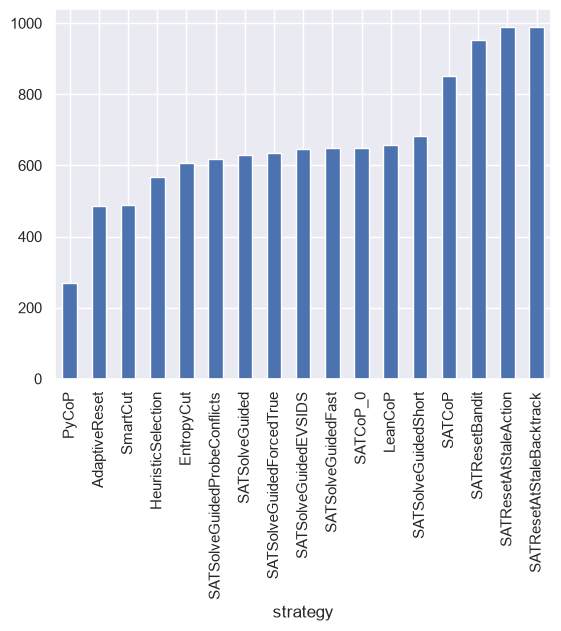

In [14]:
data[data.solved].strategy.value_counts(ascending = True).plot.bar()

In [15]:
data[data.strategy == 'SATResetAtStaleAction'].result.value_counts()

result
Theorem (SAT)                             988
Non-Theorem: no positive start clauses      1
Name: count, dtype: int64

In [16]:
data[data.strategy == 'SATResetAtTwo'].result.value_counts()

Series([], Name: count, dtype: int64)

In [17]:
merged = pandas.merge(
    data,
    data,
    left_on = 'problem',
    right_on = 'problem',
    suffixes = ('_left', '_right'),
)

In [18]:
pandas.crosstab(merged.strategy_left, merged.strategy_right)

strategy_right,AdaptiveReset,EntropyCut,HeuristicSelection,LeanCoP,PyCoP,SATCoP,SATCoP_0,SATResetAtStaleAction,SATResetAtStaleBacktrack,SATResetBandit,SATSolveGuided,SATSolveGuidedEVSIDS,SATSolveGuidedFast,SATSolveGuidedForcedTrue,SATSolveGuidedProbeConflicts,SATSolveGuidedShort,SmartCut
strategy_left,,,,,,,,,,,,,,,,,
AdaptiveReset,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013
EntropyCut,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013
HeuristicSelection,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013
LeanCoP,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013
PyCoP,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013
SATCoP,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013
SATCoP_0,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013
SATResetAtStaleAction,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013
SATResetAtStaleBacktrack,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013,5013


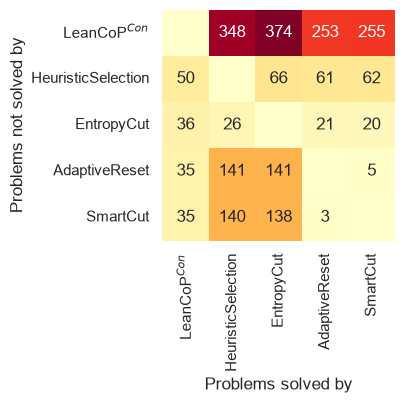

In [19]:
values = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
)

order = values.groupby(level = 'strategy_right').sum().sort_values().index

results = (
    values
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'Loser', columns = 'Winner')
    .reindex(index = order, columns = order, fill_value = 0)
)

renamer = {
    'PyCoP': 'LeanCoP${}^{Con}$',
}

cols = ['PyCoP', 'HeuristicSelection', 'EntropyCut', 'AdaptiveReset', 'SmartCut']
plot = (
    results.
    loc[cols, cols].
    rename_axis(index = 'Problems not solved by', columns = 'Problems solved by').
    rename(index = renamer).
    rename(columns = renamer)
)

fig, ax = pyplot.subplots(figsize = (3, 3))
seaborn.heatmap(
    plot,
    annot = plot.astype(str).where(~numpy.eye(plot.index.size, dtype = bool), other = ''),
    fmt = 's',
    cmap = 'YlOrRd',
    cbar = False,
    ax = ax,
)

# pyplot.xticks(rotation = 72, ha = 'right')
fig.savefig('figures/report/heuristic_policies.png', bbox_inches = 'tight', dpi = 400)
# pyplot.title(f'Winners and losers of different SAT policies. Total of {merged.problem.nunique():,d} problems.')
# pyplot.savefig('figures/sat_policies_plot_29Apr.png', bbox_inches = 'tight', dpi = 400)

In [20]:
results.columns

Index(['PyCoP', 'AdaptiveReset', 'SmartCut', 'HeuristicSelection',
       'SATSolveGuidedProbeConflicts', 'SATSolveGuided',
       'SATSolveGuidedForcedTrue', 'EntropyCut', 'SATSolveGuidedEVSIDS',
       'SATCoP_0', 'SATSolveGuidedFast', 'LeanCoP', 'SATSolveGuidedShort',
       'SATCoP', 'SATResetBandit', 'SATResetAtStaleAction',
       'SATResetAtStaleBacktrack'],
      dtype='object', name='strategy_right')

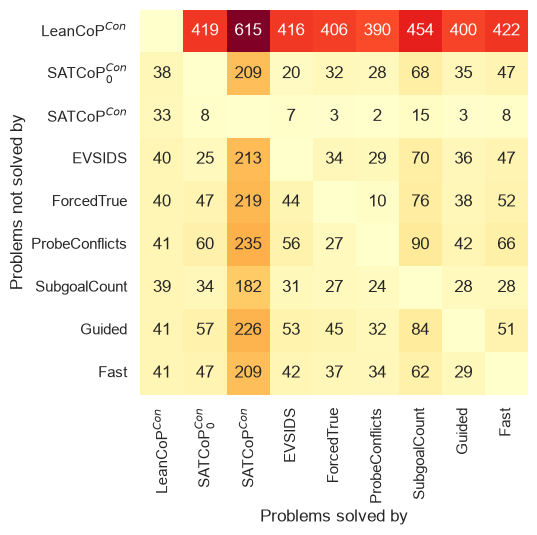

In [21]:
values = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
)

order = values.groupby(level = 'strategy_right').sum().sort_values().index

results = (
    values
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'Loser', columns = 'Winner')
    .reindex(index = order, columns = order, fill_value = 0)
)

def renamer(x):
    renamed = {
        'PyCoP': 'LeanCoP${}^{Con}$',
        'SATCoP_0': 'SATCoP${}_0^{Con}$',
        'SATCoP': 'SATCoP${}^{Con}$',
        'SATSolveGuidedShort': 'SATSolveGuidedSubgoalCount',
    }
    x = renamed.get(x, x)

    if x == 'SATSolveGuided':
        return 'Guided'

    return x.removeprefix('SATSolveGuided')

cols = ['PyCoP', 'SATCoP_0', 'SATCoP', 'SATSolveGuidedEVSIDS', 'SATSolveGuidedForcedTrue', 'SATSolveGuidedProbeConflicts', 'SATSolveGuidedShort', 'SATSolveGuided', 'SATSolveGuidedFast']
plot = (
    results.
    loc[cols, cols].
    rename_axis(index = 'Problems not solved by', columns = 'Problems solved by').
    rename(index = renamer).
    rename(columns = renamer)
)

fig, ax = pyplot.subplots(figsize = (5, 5))
seaborn.heatmap(
    plot,
    annot = plot.astype(str).where(~numpy.eye(plot.index.size, dtype = bool), other = ''),
    fmt = 's',
    cmap = 'YlOrRd',
    cbar = False,
    ax = ax,
)

fig.savefig('figures/report/sat_guide_policies.png', bbox_inches = 'tight', dpi = 400)

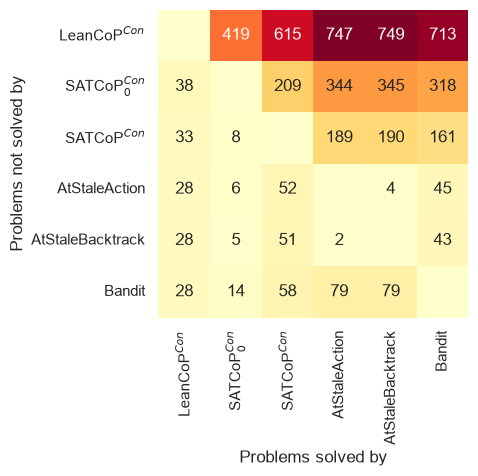

In [22]:
values = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
)

order = values.groupby(level = 'strategy_right').sum().sort_values().index

results = (
    values
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'Loser', columns = 'Winner')
    .reindex(index = order, columns = order, fill_value = 0)
)

def renamer(x):
    renamed = {
        'PyCoP': 'LeanCoP${}^{Con}$',
        'SATCoP_0': 'SATCoP${}_0^{Con}$',
        'SATCoP': 'SATCoP${}^{Con}$',
        'SATSolveGuidedShort': 'SATSolveGuidedSubgoalCount',
    }
    x = renamed.get(x, x)

    if x == 'SATSolveGuided':
        return 'Guided'

    return x.removeprefix('SATReset')

cols = ['PyCoP', 'SATCoP_0', 'SATCoP', 'SATResetAtStaleAction', 'SATResetAtStaleBacktrack', 'SATResetBandit']
plot = (
    results.
    loc[cols, cols].
    rename_axis(index = 'Problems not solved by', columns = 'Problems solved by').
    rename(index = renamer).
    rename(columns = renamer)
)

fig, ax = pyplot.subplots(figsize = (4, 4))
seaborn.heatmap(
    plot,
    annot = plot.astype(str).where(~numpy.eye(plot.index.size, dtype = bool), other = ''),
    fmt = 's',
    cmap = 'YlOrRd',
    cbar = False,
    ax = ax,
)

fig.savefig('figures/report/sat_reset_policies.png', bbox_inches = 'tight', dpi = 400)

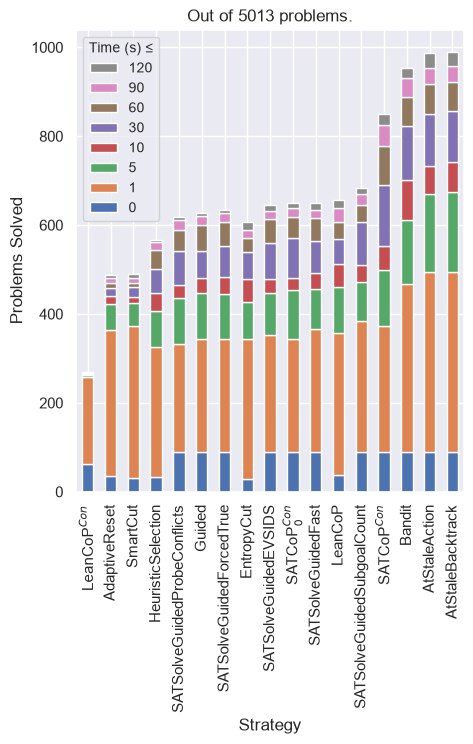

In [23]:
pyplot.rcParams["figure.figsize"] = (5,6)

times = [0, 1, 5, 10, 30, 60, 90, 120]
solved_time = Series(
    numpy.select(
        [data.solved & (data.time_ms <= 1000 * x) for x in times],
        [x for x in times],
        default = None,
    ),
    index = data.index,
    name = 'solved_time',
)

q = pandas.concat([data, solved_time], axis = 1)[['strategy', 'solved_time']]
b = q.groupby('strategy').value_counts(sort = False).sort_index(level = [0, 1]).unstack().reindex(order).rename(index = renamer)
b.plot.bar(stacked = True)
pyplot.ylabel('Problems Solved')
pyplot.xlabel('Strategy')
pyplot.legend(loc = 0, fontsize = 'small', reverse = True, title = 'Time (s) ≤', title_fontsize = 'small')

pyplot.title(f'Out of {data.problem.nunique()} problems.')
None

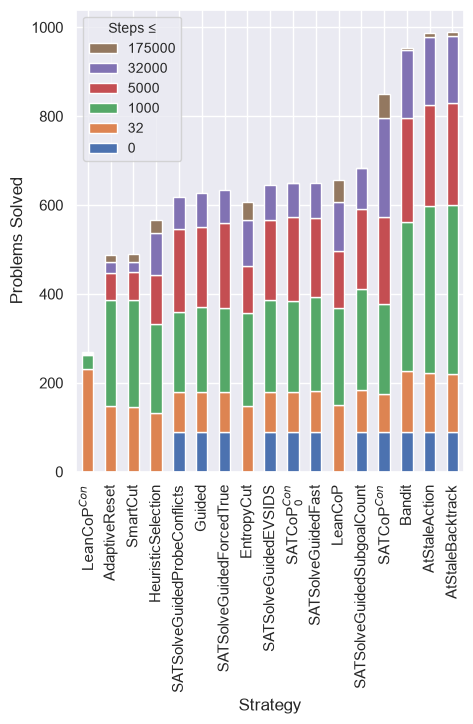

In [24]:
pyplot.rcParams["figure.figsize"] = (5,6)

times = [0, 32, 1000, 5000, 32000, 175000, 1000000]
solved_time = Series(
    numpy.select(
        [data.solved & (data.steps <= x) for x in times],
        [x for x in times],
        default = None,
    ),
    index = data.index,
    name = 'solved_time',
)

q = pandas.concat([data, solved_time], axis = 1)[['strategy', 'solved_time']]
b = q.groupby('strategy').value_counts(sort = False).sort_index(level = [0, 1]).unstack().reindex(order).rename(index = renamer)
b.plot.bar(stacked = True)
pyplot.ylabel('Problems Solved')
pyplot.xlabel('Strategy')
pyplot.legend(loc = 0, fontsize = 'small', reverse = True, title = 'Steps ≤', title_fontsize = 'small')

In [25]:
merged.strategy_right.unique()

array(['PyCoP', 'LeanCoP', 'SATCoP_0', 'SATCoP', 'HeuristicSelection',
       'EntropyCut', 'AdaptiveReset', 'SATSolveGuided',
       'SATSolveGuidedProbeConflicts', 'SmartCut',
       'SATSolveGuidedForcedTrue', 'SATSolveGuidedEVSIDS',
       'SATSolveGuidedShort', 'SATSolveGuidedFast',
       'SATResetAtStaleAction', 'SATResetAtStaleBacktrack',
       'SATResetBandit'], dtype=object)

In [26]:
merged[(merged.strategy_left == 'SATSolveLiteral') & (merged.strategy_right == 'SATResetAtStaleAction') & merged.solved_right & merged.solved_left][['problem', 'steps_left', 'steps_right']]

,problem,steps_left,steps_right


In [27]:
merged.columns

Index(['problem', 'strategy_left', 'status_left', 'result_left', 'solved_left',
       'steps_left', 'time_ms_left', 'problem_spc_tags_left',
       'problem_typed_left', 'problem_declared_status_left',
       'problem_declared_status_kind_left', 'info_left', 'error_left',
       'strategy_right', 'status_right', 'result_right', 'solved_right',
       'steps_right', 'time_ms_right', 'problem_spc_tags_right',
       'problem_typed_right', 'problem_declared_status_right',
       'problem_declared_status_kind_right', 'info_right', 'error_right'],
      dtype='object')

In [28]:
merged[
    (merged.strategy_left == 'FirstAction') &
    (merged.strategy_right == 'SATSolve') &
    merged.solved_right &
    merged.solved_left &
    (merged.steps_right == 0) &
    (merged.steps_left < 10000)
    ][['problem', 'time_ms_left', 'steps_left', 'time_ms_right', 'steps_right']].sort_values('steps_left', ascending = False)

,problem,time_ms_left,steps_left,time_ms_right,steps_right
